# Healthcare Data Analytics: Inpatient Admission & Clinical Trends
### Comprehensive Data Cleaning, Feature Engineering, Relational Database Ingestion & Business Analytics
**Dataset**: 55,500 Inpatient Admissions across Demographics, Clinical Conditions, Medications, Insurance and Billing


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load healthcare dataset
df = pd.read_csv("healthcare_dataset.csv")

df.head()


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [2]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
dtypes: float64(1), int64(2), str(12)
memory usage: 12.3 MB


In [3]:
df.describe(include='all')


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
count,55500,55500.000000,55500,55500,55500,55500,55500,55500,55500,55500.000000,55500.000000,55500,55500,55500,55500
unique,49992,NaN,2,8,6,1827,40341,39876,5,NaN,NaN,3,1856,5,3
top,DAvId muNoZ,NaN,Male,A-,Arthritis,2024-03-16,Michael Smith,LLC Smith,Cigna,NaN,NaN,Elective,2020-03-15,Lipitor,Abnormal
freq,3,NaN,27774,6969,9308,50,27,44,11249,NaN,NaN,18655,53,11140,18627
mean,NaN,51.539459,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25539.316097,301.134829,NaN,NaN,NaN,NaN
std,NaN,19.602454,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14211.454431,115.243069,NaN,NaN,NaN,NaN
min,NaN,13.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2008.492140,101.000000,NaN,NaN,NaN,NaN
25%,NaN,35.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13241.224652,202.000000,NaN,NaN,NaN,NaN
50%,NaN,52.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25538.069376,302.000000,NaN,NaN,NaN,NaN
75%,NaN,68.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37820.508436,401.000000,NaN,NaN,NaN,NaN


In [4]:
df.isnull().sum()


Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

## Data Cleaning and Preprocessing
- Standardize patient names to Proper Title Case
- Address invalid negative billing values by taking absolute values
- Normalize column names to lowercase snake_case format


In [5]:
# Standardize inconsistent casing in patient names
df["Name"] = df["Name"].str.title()

# Rectify negative billing amounts (data entry errors / refund adjustments)
df["Billing Amount"] = df["Billing Amount"].abs().round(2)
df[["Name", "Billing Amount"]].head()


,Name,Billing Amount
0,Bobby Jackson,18856.28
1,Leslie Terry,33643.33
2,Danny Smith,27955.10
3,Andrew Watts,37909.78
4,Adrienne Bell,14238.32


In [6]:
df.columns = df.columns.str.lower().str.replace(" ", "_")
df.columns


Index(['name', 'age', 'gender', 'blood_type', 'medical_condition',
       'date_of_admission', 'doctor', 'hospital', 'insurance_provider',
       'billing_amount', 'room_number', 'admission_type', 'discharge_date',
       'medication', 'test_results'],
      dtype='str')

## Feature Engineering
- Convert dates to datetime and derive Length of Stay (in days)
- Segment patients into clinical age groups using quantile binning (pd.qcut)
- Create hospital stay duration segments (Short Stay, Medium Stay, Extended Stay)
- Calculate Daily Billing Rate


In [7]:
# Convert dates and engineer length of stay (days)
df["date_of_admission"] = pd.to_datetime(df["date_of_admission"])
df["discharge_date"] = pd.to_datetime(df["discharge_date"])
df["length_of_stay"] = (df["discharge_date"] - df["date_of_admission"]).dt.days
df[["date_of_admission", "discharge_date", "length_of_stay"]].head(10)


,date_of_admission,discharge_date,length_of_stay
0,2024-01-31,2024-02-02,2
1,2019-08-20,2019-08-26,6
2,2022-09-22,2022-10-07,15
3,2020-11-18,2020-12-18,30
4,2022-09-19,2022-10-09,20
5,2023-12-20,2023-12-24,4
6,2020-11-03,2020-11-15,12
7,2021-12-28,2022-01-07,10
8,2020-07-01,2020-07-14,13
9,2021-05-23,2021-06-22,30


In [8]:
# Create an age group column based on the age of patients
labels = ["young_adult", "adult", "middle_aged", "senior"]
df["age_group"] = pd.qcut(df["age"], q=4, labels=labels)
df[["age", "age_group"]].head(10)


,age,age_group
0,30,young_adult
1,62,middle_aged
2,76,senior
3,28,young_adult
4,43,adult
5,36,adult
6,21,young_adult
7,20,young_adult
8,82,senior
9,58,middle_aged


In [9]:
# Categorize length of stay into operational segments
def categorize_stay(days):
    if days <= 7:
        return "short_stay"
    elif days <= 21:
        return "medium_stay"
    else:
        return "extended_stay"

df["stay_segment"] = df["length_of_stay"].apply(categorize_stay)
df["daily_billing_rate"] = (df["billing_amount"] / df["length_of_stay"]).round(2)
df[["length_of_stay", "stay_segment", "daily_billing_rate"]].head(10)


,length_of_stay,stay_segment,daily_billing_rate
0,2,short_stay,9428.14
1,6,short_stay,5607.22
2,15,medium_stay,1863.67
3,30,extended_stay,1263.66
4,20,medium_stay,711.92
5,4,short_stay,12036.28
6,12,medium_stay,1631.74
7,10,medium_stay,4582.05
8,13,medium_stay,3855.32
9,30,extended_stay,659.49


In [10]:
# Verify cleaned schema and export dataset
print(f"Cleaned dataset shape: {df.shape}")
df.to_csv("healthcare_dataset_cleaned.csv", index=False)
print("Successfully exported cleaned data to healthcare_dataset_cleaned.csv")


Cleaned dataset shape: (55500, 19)
Successfully exported cleaned data to healthcare_dataset_cleaned.csv


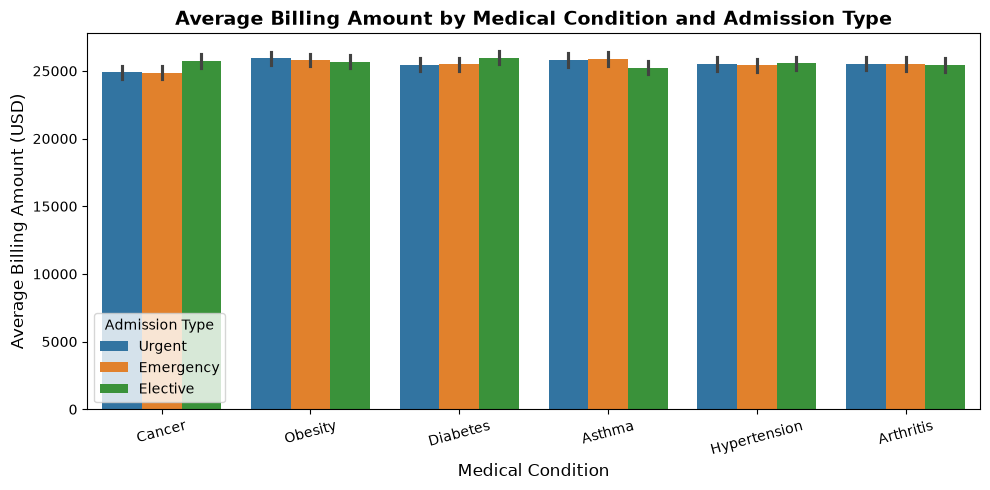

In [11]:
# Visualizing Billing Amount by Medical Condition and Admission Type
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="medical_condition", y="billing_amount", hue="admission_type", estimator=np.mean)
plt.title("Average Billing Amount by Medical Condition and Admission Type", fontsize=14, fontweight="bold")
plt.xlabel("Medical Condition", fontsize=12)
plt.ylabel("Average Billing Amount (USD)", fontsize=12)
plt.xticks(rotation=15)
plt.legend(title="Admission Type")
plt.tight_layout()
plt.savefig("healthcare_billing_analysis.png", dpi=300)
plt.show()


In [12]:
%pip install psycopg2-binary sqlalchemy 


Note: you may need to restart the kernel to use updated packages.


In [13]:
from getpass import getpass
from sqlalchemy import create_engine, URL, text

engine = create_engine(
	URL.create(
		"postgresql+psycopg2",
		username=input("Username: "),
		password=getpass("Password: "),
		host="localhost",
		port=5432,
		database="Healthcare-Data-Analytics",
	)
)

with engine.connect() as connection:
	print(connection.execute(text("SELECT 1")).scalar())


#Load the data into the database
table_name = "healthcare_data"
df.to_sql(table_name, engine, if_exists="replace", index=False)
print(f"Data loaded into the '{table_name}' table in the database.")

1
Data loaded into the 'healthcare_data' table in the database.
